# Conv Layer

## Mini-Graustufenbild erzeugen

In [29]:
import torch

x = torch.tensor(
[[[1,2,3,0,0],
 [4,5,6,0,0],
 [7,8,9,0,0],
 [0,0,0,0,0],
 [0,0,0,0,0]]], dtype=torch.float32
)

In [30]:
type(x)

torch.Tensor

In [31]:
x.shape

torch.Size([1, 5, 5])

In [32]:
x.dtype

torch.float32

## Eine Conv-Layer mit zwei Filtern erzeugen

In [25]:
import torch.nn as nn
conv = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3, bias=False)

In [26]:
type(conv)

torch.nn.modules.conv.Conv2d

## Mal die Gewichte der Filterkernel sehen

In [17]:
conv.weight

Parameter containing:
tensor([[[[ 0.0957, -0.2287, -0.1930],
          [-0.3255, -0.3203,  0.1061],
          [-0.2777, -0.3142,  0.0255]]],


        [[[ 0.3259, -0.2394, -0.2109],
          [-0.1813, -0.2790,  0.3009],
          [-0.1192,  0.1842,  0.3215]]]], requires_grad=True)

In [19]:
conv.bias is None

True

In [20]:
conv.weight.shape

torch.Size([2, 1, 3, 3])

In [33]:
conv.weight.dtype

torch.float32

## Jetzt das Bild x mit der Conv-Layer filtern

In [35]:
y = conv(x)

In [36]:
type(y)

torch.Tensor

In [37]:
y.shape

torch.Size([2, 3, 3])

In [38]:
y

tensor([[[ 3.2635, -0.3265, -2.4674],
         [ 3.7504, -0.5179, -2.0705],
         [ 3.5922,  1.4685, -1.5370]],

        [[ 4.2270,  4.2465, -0.0545],
         [ 1.3072, -0.4985, -3.8148],
         [-2.0365, -1.5175, -2.5229]]], grad_fn=<SqueezeBackward1>)

## Filterkernelmatrizen per Hand setzen

In [42]:
with torch.no_grad():
    conv.weight[0] = torch.tensor([
        [[-1,-1,-1],
         [ 0, 0, 0],
         [ 1, 1, 1]]
    ])

    conv.weight[1] = torch.tensor([
            [[-1,0,1],
             [-1,0,1],
             [-1,0,1]]
        ])

In [43]:
conv.weight

Parameter containing:
tensor([[[[-1., -1., -1.],
          [ 0.,  0.,  0.],
          [ 1.,  1.,  1.]]],


        [[[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]]]], requires_grad=True)

## Die Filterantwort verstehen

In [46]:
conv(x)

tensor([[[ 18.,  12.,   6.],
         [-15., -11.,  -6.],
         [-24., -17.,  -9.]],

        [[  6., -15., -18.],
         [  4., -13., -15.],
         [  2.,  -8.,  -9.]]], grad_fn=<SqueezeBackward1>)

In [47]:
x

tensor([[[1., 2., 3., 0., 0.],
         [4., 5., 6., 0., 0.],
         [7., 8., 9., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]])

In [45]:
conv.weight

Parameter containing:
tensor([[[[-1., -1., -1.],
          [ 0.,  0.,  0.],
          [ 1.,  1.,  1.]]],


        [[[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]]]], requires_grad=True)

In [58]:
x[0, 1:4, 1:4].flatten()

tensor([5., 6., 0., 8., 9., 0., 0., 0., 0.])

In [56]:
conv.weight[0].flatten()

tensor([-1., -1., -1.,  0.,  0.,  0.,  1.,  1.,  1.], grad_fn=<ViewBackward0>)

In [59]:
v1 = x[0, 1:4, 1:4].flatten()
v2 = conv.weight[0].flatten()
torch.dot(v1,v2)

tensor(-11., grad_fn=<DotBackward0>)

In [60]:
y.shape

torch.Size([2, 3, 3])

## Mal ein ganzes Bild filtern

In [2]:
import cv2
fname = "/home/juebrauer/link_to_vcd/08_datasets/66_test_bilder_dl4cv_ws26/campus_hochschule_kempten.png"
img = cv2.imread(fname)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

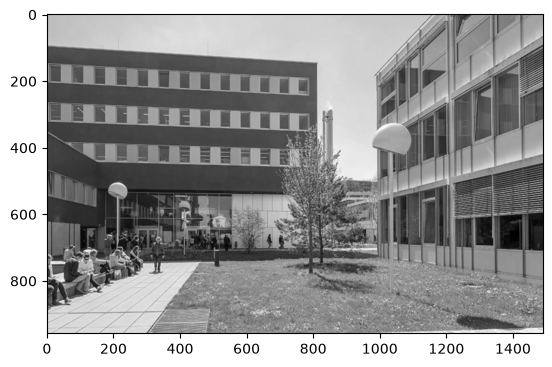

In [3]:
import matplotlib.pyplot as plt
plt.imshow(img, cmap="gray")
plt.show()

In [6]:
img.shape

(958, 1490)

In [19]:
import torchvision.transforms as transforms

transform = transforms.Compose(
    [#transforms.Resize( (128,128) ),
     transforms.ToTensor()
     ]
)

x = transform(img)


In [15]:
img.shape

(958, 1490)

In [18]:
x.shape

torch.Size([1, 1, 958, 1490])

In [20]:
import torch.nn as nn
import torch
conv = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3,
          padding=1, bias=False)

prewitt = torch.tensor([[
    [[-1,-1,-1],
     [0,0,0],
     [1,1,1]]
]])

blur = torch.tensor([[
    [[1,1,1],
     [1,1,1],
     [1,1,1]]
]]) / 9

with torch.no_grad():
    conv.weight[0] = blur
    conv.weight[1] = prewitt

    y = conv(x)

In [21]:
y.shape

torch.Size([2, 958, 1490])

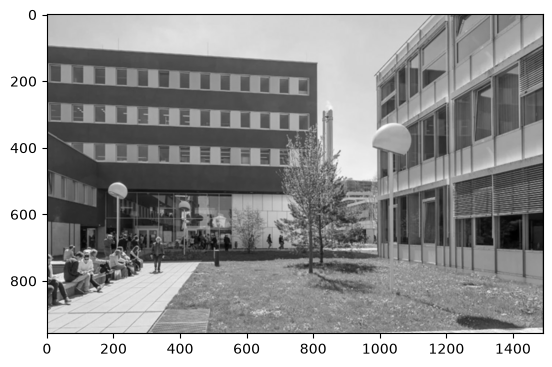

In [25]:
plt.imshow(y[0], cmap="gray")
plt.show()

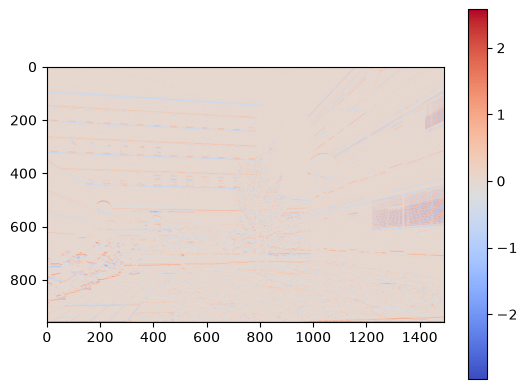

In [27]:
plt.imshow(y[1], cmap="coolwarm")
plt.colorbar()
plt.show()

In [28]:
img[:5,:5]

array([[188, 188, 188, 188, 188],
       [188, 188, 188, 188, 188],
       [188, 188, 188, 188, 188],
       [188, 188, 188, 188, 188],
       [188, 188, 188, 188, 188]], dtype=uint8)

In [29]:
x[:5,:5]

tensor([[[0.7373, 0.7373, 0.7373,  ..., 0.6392, 0.6431, 0.6431],
         [0.7373, 0.7373, 0.7373,  ..., 0.6392, 0.6431, 0.6431],
         [0.7373, 0.7373, 0.7373,  ..., 0.6392, 0.6431, 0.6431],
         [0.7373, 0.7373, 0.7373,  ..., 0.6392, 0.6431, 0.6431],
         [0.7373, 0.7373, 0.7373,  ..., 0.6392, 0.6431, 0.6431]]])

In [30]:
x.dtype

torch.float32

In [31]:
y.shape

torch.Size([2, 958, 1490])

In [33]:
y[0].min(), y[0].max()

(tensor(0.0009), tensor(0.9939))

In [34]:
y[1].min(), y[1].max()

(tensor(-2.9725), tensor(2.5765))

# Pool-Layer

In [35]:
x = torch.tensor(
[[[1,2,3,0,0],
 [4,5,6,0,0],
 [7,8,9,0,0],
 [0,0,0,0,0],
 [0,0,0,0,0]]], dtype=torch.float32
)

In [43]:
pool = nn.MaxPool2d(kernel_size=2, stride=1)
y = pool(x)

In [44]:
x

tensor([[[1., 2., 3., 0., 0.],
         [4., 5., 6., 0., 0.],
         [7., 8., 9., 0., 0.],
         [0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]])

In [49]:
x.shape

torch.Size([1, 5, 5])

In [45]:
y.shape

torch.Size([1, 4, 4])

In [46]:
y

tensor([[[5., 6., 6., 0.],
         [8., 9., 9., 0.],
         [8., 9., 9., 0.],
         [0., 0., 0., 0.]]])

# Dense Layer

In [47]:
y.flatten()

tensor([5., 6., 6., 0., 8., 9., 9., 0., 8., 9., 9., 0., 0., 0., 0., 0.])

In [48]:
len(y.flatten())

16

In [51]:
l = nn.Linear(in_features=len(y.flatten()),
              out_features=5)

In [54]:
l.weight.shape

torch.Size([5, 16])

In [55]:
l.weight[0]

tensor([-0.0742, -0.1678,  0.1999,  0.2467, -0.2019,  0.0582,  0.1172, -0.1164,
        -0.0508, -0.1498, -0.0262, -0.0678,  0.1059,  0.1496, -0.1576, -0.0523],
       grad_fn=<SelectBackward0>)

In [56]:
l.bias

Parameter containing:
tensor([-0.1024, -0.1442,  0.0573,  0.0566,  0.0980], requires_grad=True)

In [58]:
l(y.flatten())

tensor([-2.3078, -2.2654,  4.4224,  2.1378,  0.1272], grad_fn=<ViewBackward0>)

In [59]:
x = y.flatten()
W = l.weight
b = l.bias

x @ W.T + b

tensor([-2.3078, -2.2654,  4.4224,  2.1378,  0.1272], grad_fn=<AddBackward0>)

In [60]:
type(x), type(W)

(torch.Tensor, torch.nn.parameter.Parameter)

In [61]:
x.shape

torch.Size([16])

In [64]:
W.T.shape

torch.Size([16, 5])

In [65]:
b.shape

torch.Size([5])